# 01 — Explore the dataset

**What's in a bundle** (built by `uv run oracle dataset`):

| file | one row per | used for |
|---|---|---|
| `matches.parquet` | game | the win model: `y_blue_win` + `d_*` (blue − red), `lane_*`, `ctx_*` features |
| `seats.parquet` | player in a game | per-player features (joke material) and labels `y_kills`, `y_deaths`, … for the performance models later |
| `manifest.json` | — | dataset id, cut-off, params, patches, column groups, a definition of every feature |

Every feature was computed **only from games that ended before this game started** (enforced and tested in
`src/oracle/features`). So nothing here can leak the result. This notebook just looks at the data before modelling it.

In [1]:
# Setup: works locally (Jupyter started in the repo or in training/) and on Google Colab.
import os, sys, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/oracle-training")   # <- the folder you uploaded (see training/README.md)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "lightgbm", "shap"], check=True)
else:
    ROOT = Path.cwd() if (Path.cwd() / "trainlib.py").exists() else Path.cwd() / "training"
sys.path.insert(0, str(ROOT))

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import trainlib as tl

# Known harmless library notices (kept out of the saved outputs):
warnings.filterwarnings("ignore", message=".*eval_set.*deprecated")              # LightGBM 4.7 rename; old name works everywhere
warnings.filterwarnings("ignore", message="IProgress not found")                  # shap's progress bar widget
warnings.filterwarnings("ignore", message="LightGBM binary classifier with TreeExplainer")

SEED = 42   # passed as random_state to every model, so runs are reproducible
pd.set_option("display.width", 160, "display.max_columns", 40)

b = tl.load(os.environ.get("ORACLE_BUNDLE", ROOT / "data"))   # newest bundle in data/
print(b.describe())
if len(b.matches) < 500:
    print(f"\n!! Only {len(b.matches)} games: numbers below are mostly noise. Treat this run as a pipeline check "
          "and re-run after more crawling.")

win_v1@548a7d0e28  built 2026-11-05T11:29:28+00:00
rows: 42 matches, 420 seats (skipped: {'incomplete_history': 40})
time: ['2026-06-24T14:55+00:00', '2026-10-20T17:45+00:00']
patches: 16.13, 16.15, 16.17, 16.18, 16.19, 16.20
features: 102 match-level, 32 per seat

!! Only 42 games: numbers below are mostly noise. Treat this run as a pipeline check and re-run after more crawling.


## 1. Is blue side favoured?
The base rate everything is compared against. In League it's typically ~51–53 % for blue in solo queue.
The interval shows how much of that our sample can actually tell us.

In [2]:
y = b.matches["y_blue_win"]
p, n = y.mean(), len(y)
se = np.sqrt(p * (1 - p) / n)
print(f"blue win rate {p:.3f}  (95% CI {p - 1.96 * se:.3f} .. {p + 1.96 * se:.3f}, n = {n})")

blue win rate 0.571  (95% CI 0.422 .. 0.721, n = 42)


## 2. What is missing?
`NaN` means "unknown", not zero: no history for a new account, no clean rank snapshot, never played the champion
(`days_since_champ`). Rank and mastery stay empty until `oracle crawl --forever` has captured rank/mastery
**at game start** for enough games. Snapshots taken after a game would leak (they include that game's LP).

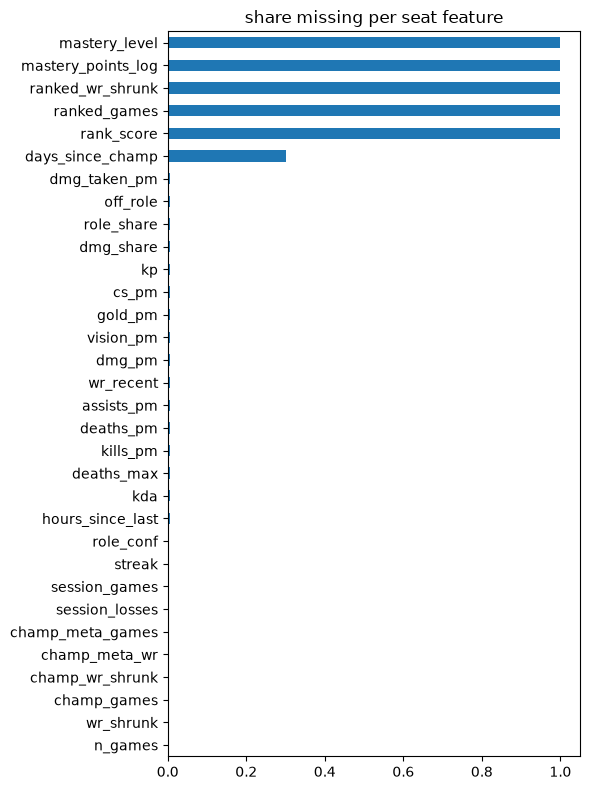

In [3]:
sf = b.manifest["columns"]["seat_features"]
missing = b.seats[sf].isna().mean().sort_values(ascending=False)
ax = missing.plot.barh(figsize=(6, 8), title="share missing per seat feature")
ax.invert_yaxis(); plt.tight_layout(); plt.show()

## 3. How good is the role inference?
The spectator API (what the bot sees) has no roles, so roles are **inferred** from each player's history plus the
champion's usual lane, with one player per role per team. The true role is kept only to measure this.

In [4]:
acc = (b.seats["true_role"] == b.seats["role"]).mean()
print(f"role inference accuracy: {acc:.1%}")
pd.crosstab(b.seats["true_role"], b.seats["role"], rownames=["true"], colnames=["inferred"])

role inference accuracy: 81.4%


inferred,BOTTOM,JUNGLE,MIDDLE,TOP,UTILITY
true,,,,,
BOTTOM,72,3,2,3,4
JUNGLE,3,66,4,8,3
MIDDLE,3,3,70,8,0
TOP,3,10,8,60,3
UTILITY,3,2,0,5,74


## 4. Which per-player features relate to winning? (descriptive)
AUC of each feature against the player's own `y_win`, one row per player. 0.5 = no relation; 0.55 is
already notable for a pre-game signal. Caveat: 10 rows per game are correlated and teammates share the label,
so read this as a ranking, not as significance.

In [5]:
from sklearn.metrics import roc_auc_score

def auc_table(df, cols, label):
    rows = []
    for c in cols:
        ok = df[c].notna()
        if ok.sum() > 20 and df.loc[ok, label].nunique() == 2 and df.loc[ok, c].nunique() > 1:
            rows.append((c, roc_auc_score(df.loc[ok, label], df.loc[ok, c]), ok.mean()))
    t = pd.DataFrame(rows, columns=["feature", "auc", "coverage"]).set_index("feature")
    return t.assign(strength=(t["auc"] - 0.5).abs()).sort_values("strength", ascending=False).round(3)

auc_table(b.seats, sf, "y_win")

,auc,coverage,strength
feature,,,
session_losses,0.579,1.000,0.079
streak,0.438,1.000,0.062
wr_recent,0.441,0.995,0.059
session_games,0.548,1.000,0.048
champ_games,0.542,1.000,0.042
champ_meta_wr,0.465,1.000,0.035
deaths_pm,0.526,0.995,0.026
gold_pm,0.525,0.995,0.025
role_conf,0.475,1.000,0.025


## 5. The same at match level (blue − red differences)
This is what the win model sees. Team-mean differences are noisier than you'd hope: matchmaking already tries to
make both teams equal, so the *remaining* differences are small.

In [6]:
auc_table(b.matches, b.feature_group("d_mean_", "d_min_", "d_max_"), "y_blue_win").head(20)

,auc,coverage,strength
feature,,,
d_mean_session_losses,0.672,1.0,0.172
d_mean_streak,0.331,1.0,0.169
d_mean_wr_recent,0.341,1.0,0.159
d_min_wr_shrunk,0.623,1.0,0.123
d_mean_champ_meta_wr,0.382,1.0,0.118
d_mean_days_since_champ,0.609,1.0,0.109
d_mean_champ_meta_games,0.597,1.0,0.097
d_mean_gold_pm,0.595,1.0,0.095
d_min_champ_meta_wr,0.410,1.0,0.090


## 6. Redundancy between features
Highly correlated features (e.g. `gold_pm` and `cs_pm`) share information. Logistic regression's coefficients
get unstable with them (regularisation helps); trees don't mind much. Good to know before reading coefficients.

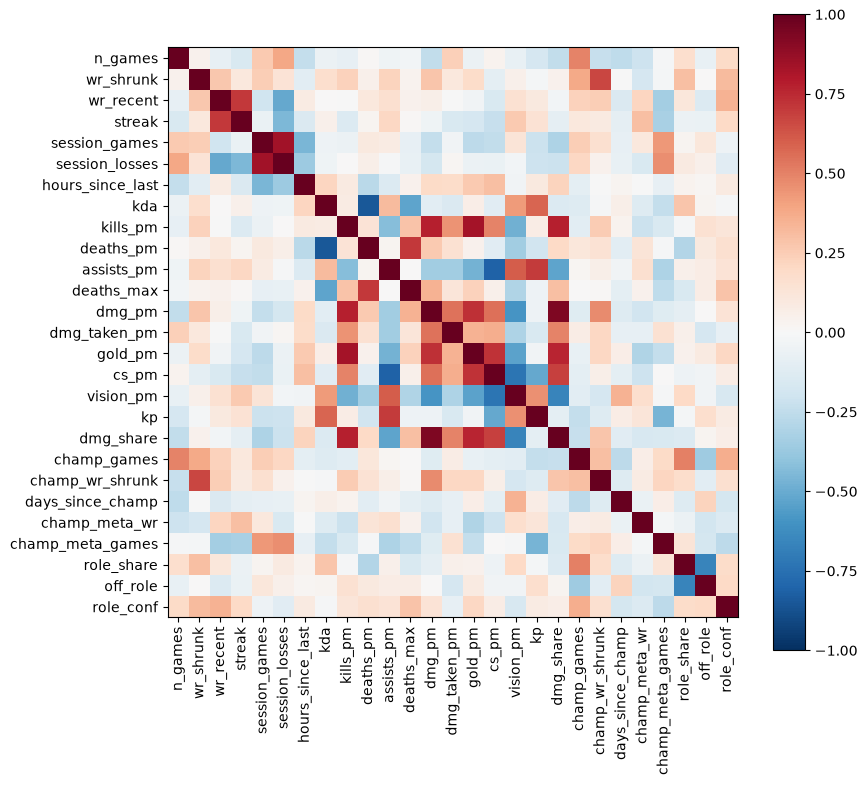

In [7]:
cols = [c for c in b.feature_group("d_mean_") if b.matches[c].notna().mean() > 0.5]
corr = b.matches[cols].corr()
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), [c.removeprefix("d_mean_") for c in cols], rotation=90)
ax.set_yticks(range(len(cols)), [c.removeprefix("d_mean_") for c in cols])
fig.colorbar(im); plt.tight_layout(); plt.show()

## 7. Feature dictionary
Every seat feature, how it's defined and why it might predict (from the manifest).

In [8]:
pd.DataFrame(b.manifest["feature_docs"], index=["definition", "why"]).T

,definition,why
n_games,usable history games (0..history_n),new / returning / smurf accounts; data quality
wr_shrunk,"(W + k/2) / (N + k), k = kappa_player",form matchmaking hasn't absorbed yet (weak: ex...
wr_recent,raw win share in the last recent_n games,short-term form
streak,"signed run from the most recent game, +W / -L,...",momentum or tilt; joke material
session_games,games that ended within session_hours before T,long sessions: fatigue / tilt
session_losses,losses among those,tilt queue
hours_since_last,log1p(hours since the last usable game ended),rust after a break
kda,ln((K + A + 1) / (D + 1)),skill beyond W/L
kills_pm,kills per minute,aggression / carry potential
deaths_pm,deaths per minute,feeding
